<a href="https://colab.research.google.com/github/EmiBonClay/Best-README-Template/blob/main/Orchidaceae_cl_hub.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Orchidaceae
Chile continental

Participa del [VII Monitoreo de Orquídeas Chilenas 2026-27]('https://inaturalist.mma.gob.cl/projects/vii-monitoreo-de-orquideas-chilenas-2026-27?tab=observers')

Te invitamos a ser parte de la séptima versión de este proyecto de Ciencia Ciudadana, para que juntos podamos conservar las orquídeas chilenas!! El objetivo es levantar información sobre la distribución, el tamaño de sus poblaciones y las posibles amenazas de nuestras orquídeas. Este monitoreo se realizará cada año para ir evaluando el estado de las poblaciones de orquídeas en el tiempo.
El Monitoreo Nacional de Orquídeas Chilenas Temporada 2026-2027 es organizado por el Centro de Conservación de Orquídeas Chilenas (CECORCH) junto al Ministerio de Medio Ambiente y la Red Chilena de Jardínes Botánicos.
Para más información, síguenos en ig: @centro_cecorch

Librería pygibf

In [ ]:
!pip install pygbif

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.4/101.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 2.5 MB/s eta 0:00:00


Librerías importadas

In [ ]:
import pandas as pd ## manipulación de dataframes
from pygbif import occurrences as occ ## módulo de ocurrencias de GBIF
from pygbif import species ## módulo de especies GBIF
import plotly.express as px

import numpy as np
import os ## permite la conexión autenticada

import matplotlib.pyplot as plt
import seaborn as sns


Variables de sesión

In [ ]:
# @title
os.environ['GBIF_USER']="lmenzelr"
os.environ['GBIF_PWD']=""
os.environ['GBIF_EMAIL']="lmenzelr@estudiante.uc.cl"

Exploración de familia

In [ ]:
species.name_backbone('Orchidaceae',taxonRank='family')

{'usage': {'key': 'DPL',
  'name': 'Orchidaceae Juss.',
  'canonicalName': 'Orchidaceae',
  'authorship': 'Juss.',
  'rank': 'FAMILY',
  'code': 'BOTANICAL',
  'status': 'ACCEPTED',
  'type': 'SCIENTIFIC',
  'formattedName': '<i>Orchidaceae</i> Juss.'},
 'classification': [{'key': 'CS5HF', 'name': 'Eukaryota', 'rank': 'DOMAIN'},
  {'key': 'P', 'name': 'Plantae', 'rank': 'KINGDOM'},
  {'key': 'CMQ8S', 'name': 'Pteridobiotina', 'rank': 'SUBKINGDOM'},
  {'key': 'TP', 'name': 'Tracheophyta', 'rank': 'PHYLUM'},
  {'key': 'L2L', 'name': 'Liliopsida', 'rank': 'CLASS'},
  {'key': 'SP', 'name': 'Asparagales', 'rank': 'ORDER'},
  {'key': 'DPL', 'name': 'Orchidaceae', 'rank': 'FAMILY'}],
 'diagnostics': {'matchType': 'EXACT',
  'confidence': 95,
  'timeTaken': 7,
  'timings': {'nameNRank': 0,
   'sciNameMatch': 7,
   'nameParse': 0,
   'luceneMatch': 7}},
 'synonym': False,
 'left': 827022,
 'right': 872365}

In [ ]:
# Search for occurrences of Orchidaceae (taxonKey: 7689) in Chile (country code: CL)
chile_orchids = occ.search(taxonKey=7689, country='CL', limit=300)

# Convert results to a DataFrame for easier reading
import pandas as pd
df_occurrences = pd.DataFrame(chile_orchids['results'])

# Extract unique species names observed in Chile
if 'species' in df_occurrences.columns:
    df_species = df_occurrences[['species', 'scientificName', 'decimalLatitude', 'decimalLongitude']].dropna(subset=['species']).drop_duplicates(subset=['species'])
    print(f"Found {len(df_species)} unique orchid species in the retrieved records:")
    display(df_species.head(10))
else:
    print("No species column found in the occurrences data.")

/tmp/ipykernel_1332/4176100401.py:2: DeprecationWarning: Numeric taxonomy keys detected. Automatically switching to GBIF Backbone taxonomy. GBIF Backbone taxonomy is outdated. Please migrate to COL Extended Release with alphanumeric keys. Use pygbif.species.gbif_to_col() to convert your numeric GBIF keys to COL alphanumeric keys.
  chile_orchids = occ.search(taxonKey=7689, country='CL', limit=300)


Found 27 unique orchid species in the retrieved records:


,species,scientificName,decimalLatitude,decimalLongitude
0,Codonorchis lessonii,Codonorchis lessonii (d'Urv.) Lindl.,-50.943930,-72.936262
1,Chloraea magellanica,Chloraea magellanica Hook.f.,-50.973767,-72.891657
4,Gavilea araucana,Gavilea araucana (Phil.) M.N.Correa,-51.554939,-72.628815
5,Chloraea piquichen,Chloraea piquichen (Lam.) Lindl.,-37.560527,-73.228885
9,Gavilea lutea,Gavilea lutea (Comm. ex Pers.) M.N.Correa,-50.947412,-72.931170
14,Myrosmodes nervosa,"Myrosmodes nervosa (Kraenzl.) Novoa, C.A.Varga...",-19.253011,-68.882647
15,Brachystele unilateralis,Brachystele unilateralis (Poir.) Schltr.,-42.512229,-74.183342
16,Chloraea alpina,Chloraea alpina Poepp.,-45.608043,-72.074906
23,Chloraea barbata,Chloraea barbata Lindl.,-37.770855,-72.806512
26,Chloraea longipetala,Chloraea longipetala Lindl.,-37.563019,-73.226555


In [ ]:
df_species.shape

(27, 4)

In [ ]:
df_species.info()

<class 'pandas.core.frame.DataFrame'>
Index: 27 entries, 0 to 288
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   species           27 non-null     object 
 1   scientificName    27 non-null     object 
 2   decimalLatitude   27 non-null     float64
 3   decimalLongitude  27 non-null     float64
dtypes: float64(2), object(2)
memory usage: 1.1+ KB


In [ ]:
# Initiate an occurrence download for Orchidaceae (taxonKey: 7689) in Chile ('CL')
# Note: This requires valid GBIF credentials in the environment (GBIF_USER, GBIF_PWD, GBIF_EMAIL)
def Download():
  download_query = [
      'taxonKey = 7689',
      'country = CL'
  ]

  # occ.download takes predicates as arguments and triggers the download on GBIF servers
  try:
      download_key = occ.download(download_query)
      print("Download initiated successfully!")
      print(f"Download Key / ID: {download_key[0]}")
      print("You can check the status of your download using:")
      print(f"occ.download_meta('{download_key[0]}')")
  except Exception as e:
      print("An error occurred while attempting the download:")
      print(e)
  return download_key[0]

In [ ]:
#Download

In [ ]:
# Check the status of the GBIF occurrence download
download_status = occ.download_meta('0010041-260928105237408')
print(f"Current status: {download_status['status']}")

# If successful, you will be able to retrieve the file using:
# occ.download_get('0010041-260928105237408')

Current status: SUCCEEDED


In [ ]:
source_orchidaceae = occ.download_get('0010041-260928105237408')

In [ ]:
url = source_orchidaceae['path']

In [ ]:
df = pd.read_csv(url,compression='zip', sep='\t')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14101 entries, 0 to 14100
Data columns (total 50 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   gbifID                            14101 non-null  int64  
 1   datasetKey                        14101 non-null  object 
 2   occurrenceID                      13762 non-null  object 
 3   kingdom                           14101 non-null  object 
 4   phylum                            14101 non-null  object 
 5   class                             14101 non-null  object 
 6   order                             14101 non-null  object 
 7   family                            14101 non-null  object 
 8   genus                             14036 non-null  object 
 9   species                           13737 non-null  object 
 10  infraspecificEpithet              28 non-null     object 
 11  taxonRank                         14101 non-null  object 
 12  scie

In [ ]:
# Print columns that have 70% or more missing (NaN) values

for col in df.columns:
  if df[col].isna().sum() / len(df) >= 0.5:
    df = df.drop(col, axis=1)

In [ ]:
mask_lon = (df['decimalLongitude'] < -65) & (df['decimalLongitude'] > -75)
mask_lat = (df['decimalLatitude'] < -30) & (df['decimalLatitude'] > -40)
df = df[mask_lon]
df = df[mask_lat]

/tmp/ipykernel_1332/417497951.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df = df[mask_lat]


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10320 entries, 0 to 14078
Data columns (total 37 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   gbifID                  10320 non-null  int64  
 1   datasetKey              10320 non-null  object 
 2   occurrenceID            10245 non-null  object 
 3   kingdom                 10320 non-null  object 
 4   phylum                  10320 non-null  object 
 5   class                   10320 non-null  object 
 6   order                   10320 non-null  object 
 7   family                  10320 non-null  object 
 8   genus                   10310 non-null  object 
 9   species                 10273 non-null  object 
 10  taxonRank               10320 non-null  object 
 11  scientificName          10320 non-null  object 
 12  verbatimScientificName  7148 non-null   object 
 13  countryCode             10320 non-null  object 
 14  locality                5666 non-null   obj

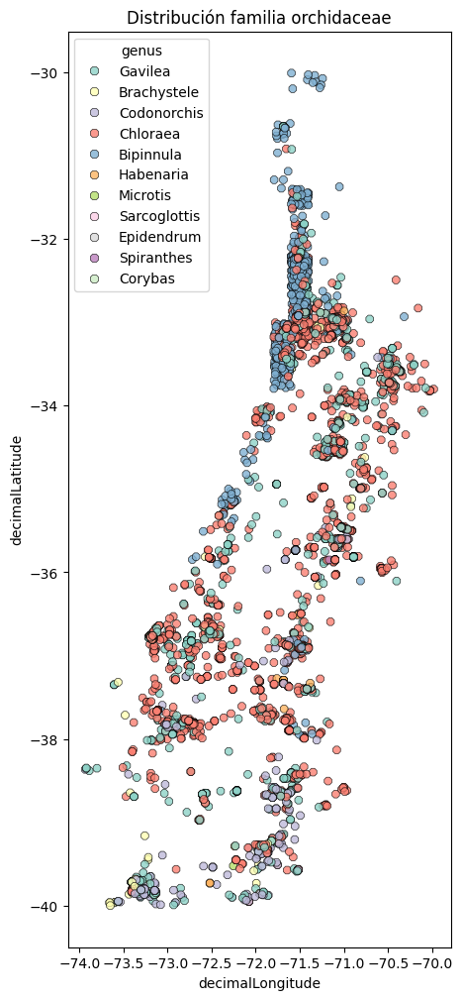

In [ ]:
fig,ax = plt.subplots(figsize=(5,12))
ax = sns.scatterplot(data=df,
                     y='decimalLatitude',
                     x = 'decimalLongitude',
                     hue= 'genus',
                     palette='Set3',
                     marker='8',
                     edgecolor='black',
                     linewidth=0.5,
                     alpha=0.8).set_title('Distribución familia orchidaceae')
plt.show()

In [ ]:
year_mask = df['year']  > 2000
df = df[year_mask]

/tmp/ipykernel_1332/180918928.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=df,


<Axes: xlabel='year', ylabel='Count'>

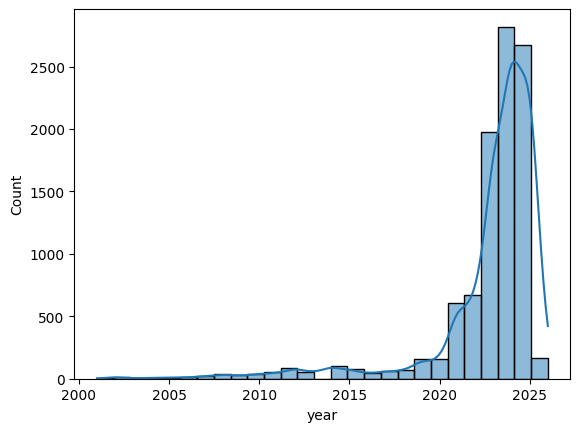

In [ ]:
bins = 2027 - 2000
sns.histplot(data=df,
             x='year',
             bins = bins,
             palette='Set3',
             kde=True,
#             hue='month'
             )

/tmp/ipykernel_1332/3725943321.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=df,


<Axes: xlabel='month', ylabel='Count'>

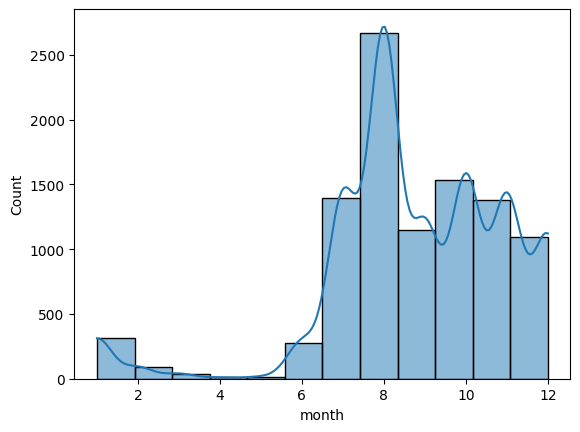

In [ ]:
sns.histplot(data=df,
             x='month',
             bins = 12,
             palette='Set3',
             kde=True,
#             hue='month'
             )

In [ ]:
df_grouped  = df.groupby(by=['genus','species'])['year'].count()
df_grouped.sort_values(ascending=False, inplace=True)
df_grouped

genus        species                 
Bipinnula    Bipinnula fimbriata         5943
Gavilea      Gavilea longibracteata       643
Chloraea     Chloraea bletioides          428
             Chloraea chrysantha          373
             Chloraea gavilu              292
Codonorchis  Codonorchis lessonii         288
Chloraea     Chloraea multiflora          168
Gavilea      Gavilea araucana             162
Chloraea     Chloraea piquichen           149
Brachystele  Brachystele unilateralis     135
Gavilea      Gavilea odoratissima         121
Chloraea     Chloraea alpina              109
             Chloraea galeata             104
             Chloraea nudilabia            89
             Chloraea disoides             81
             Chloraea cristata             76
             Chloraea magellanica          71
Gavilea      Gavilea venosa                68
Chloraea     Chloraea longipetala          65
             Chloraea crispa               61
Bipinnula    Bipinnula plumosa             56
Chloraea     Chloraea cylindrostachya      43
Gavilea      Gavilea lutea                 41
             Gavilea platyantha            41
Chloraea     Chloraea barbata              35
             Chloraea viridiflora          34
             Chloraea prodigiosa           29
Gavilea      Gavilea glandulifera          26
Chloraea     Chloraea lamellata            22
             Chloraea tectata              22
Gavilea      Gavilea litoralis             21
Habenaria    Habenaria pumila              19
Bipinnula    Bipinnula volkmannii          17
Chloraea     Chloraea grandiflora          16
             Chloraea heteroglossa         15
             Chloraea philippii            15
             Chloraea bidentata            14
             Chloraea lechleri             11
             Chloraea fonkii               11
             Chloraea cuneata              10
Gavilea      Gavilea chica                 10
Chloraea     Chloraea apinnula              4
             Chloraea speciosa              2
             Chloraea volkmannii            2
Bipinnula    Bipinnula gabriel              1
Gavilea      Gavilea supralabellata         1
Microtis     Microtis unifolia              1
Name: year, dtype: int64

In [ ]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 27.7 MB/s eta 0:00:00


https://biopython.org/docs/dev/Tutorial/chapter_phylo.html

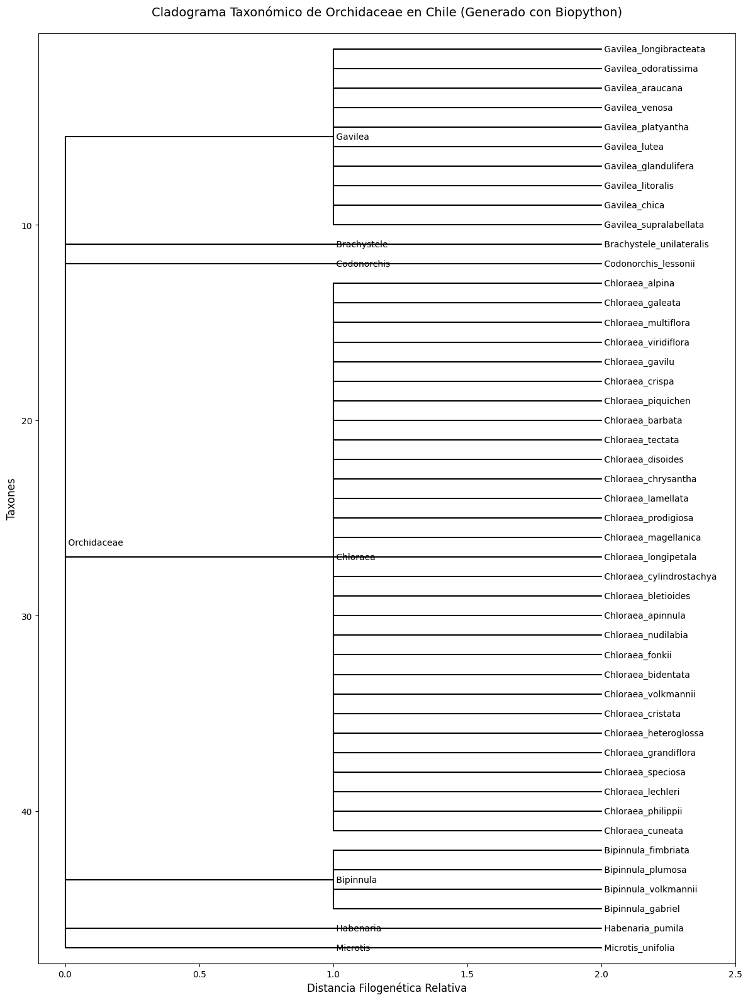

In [ ]:
import io
import matplotlib.pyplot as plt
from Bio import Phylo
from Bio.Phylo.BaseTree import Tree, Clade

# 1. Obtener la taxonomía jerárquica única desde nuestro DataFrame limpio
tax_tree_df = df[['family', 'genus', 'species']].dropna().drop_duplicates(subset=['species'])

# 2. Agrupar la taxonomía jerárquicamente para construir una estructura Newick
# Estructura: ( (Especie1, Especie2)Género1, (Especie3)Género2 )Familia
genus_groups = {}
for _, row in tax_tree_df.iterrows():
    fam = row['family']
    gen = row['genus']
    sp = row['species'].replace(' ', '_') # Los espacios no son válidos en formato estándar Newick sin comillas
    if gen not in genus_groups:
        genus_groups[gen] = []
    genus_groups[gen].append(sp)

# Construir los clados de cada género
genus_strings = []
for genus, species_list in genus_groups.items():
    species_str = ",".join(species_list)
    genus_strings.append(f"({species_str}){genus}")

# Unir todo bajo la raíz de la Familia (Orchidaceae)
newick_tree_str = f"({','.join(genus_strings)})Orchidaceae;"

# 3. Cargar el árbol Newick usando el módulo Phylo de Biopython
tree = Phylo.read(io.StringIO(newick_tree_str), "newick")

# 4. Graficar el cladograma clásico
fig = plt.figure(figsize=(12, 16), dpi=100)
ax = fig.add_subplot(1, 1, 1)

# Dibujar el árbol filogenético/taxonómico clásico
Phylo.draw(tree, axes=ax, do_show=False)

plt.title('Cladograma Taxonómico de Orchidaceae en Chile (Generado con Biopython)', fontsize=14, pad=20)
plt.xlabel('Distancia Filogenética Relativa', fontsize=12)
plt.ylabel('Taxones', fontsize=12)
plt.tight_layout()
plt.show()

## Image

In [ ]:
df['genus'].unique()

array(['Gavilea', 'Brachystele', 'Codonorchis', 'Chloraea', 'Bipinnula',
       'Habenaria', 'Microtis', nan, 'Corybas'], dtype=object)

In [ ]:
df_chloraea = df[df['genus'] == 'Chloraea']
df_reduced = df_chloraea[['genus', 'gbifID', 'species']].drop_duplicates(subset=['species'])
df_reduced

,genus,gbifID,species
5,Chloraea,6552883476,Chloraea alpina
7,Chloraea,6552878614,Chloraea galeata
8,Chloraea,6552875752,Chloraea multiflora
9,Chloraea,6552869705,Chloraea viridiflora
11,Chloraea,6552862502,Chloraea gavilu
18,Chloraea,6552734870,Chloraea crispa
19,Chloraea,6552733039,Chloraea piquichen
32,Chloraea,6552397588,Chloraea barbata
38,Chloraea,6552332184,Chloraea tectata
42,Chloraea,6552303738,Chloraea disoides


Starting image extraction and plotting for each unique order...

Attempting to get image for Order: Chloraea alpina (GBIF ID: 6552883476)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/619243780/original.jpg


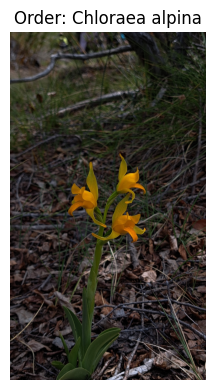


Attempting to get image for Order: Chloraea galeata (GBIF ID: 6552878614)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/737747466/original.jpg


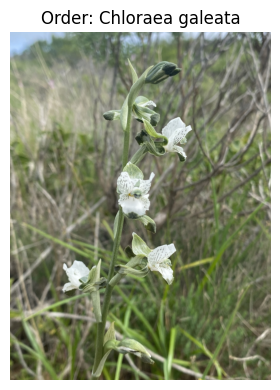


Attempting to get image for Order: Chloraea multiflora (GBIF ID: 6552875752)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/729967624/original.jpg


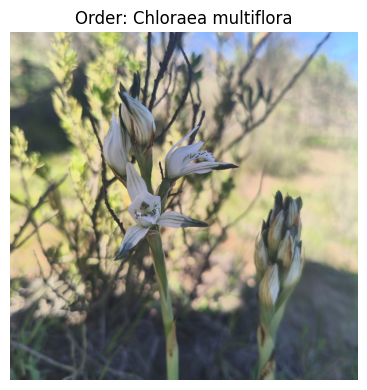


Attempting to get image for Order: Chloraea viridiflora (GBIF ID: 6552869705)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/599664532/original.jpg


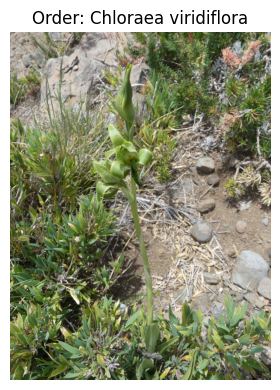


Attempting to get image for Order: Chloraea gavilu (GBIF ID: 6552862502)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/574325885/original.jpg


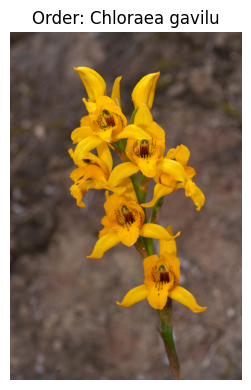


Attempting to get image for Order: Chloraea crispa (GBIF ID: 6552734870)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/592710956/original.jpg


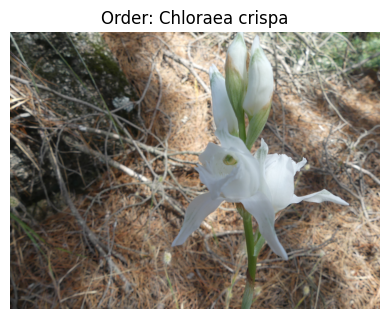


Attempting to get image for Order: Chloraea piquichen (GBIF ID: 6552733039)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/598402822/original.jpg


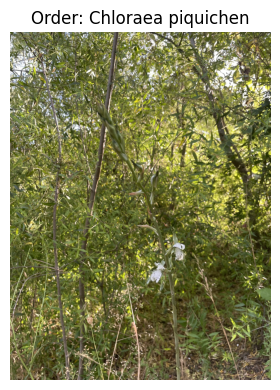


Attempting to get image for Order: Chloraea barbata (GBIF ID: 6552397588)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/606774770/original.jpg


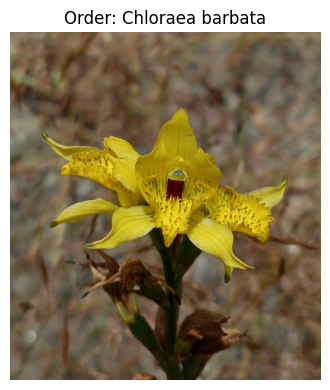


Attempting to get image for Order: Chloraea tectata (GBIF ID: 6552332184)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/599324160/original.jpg


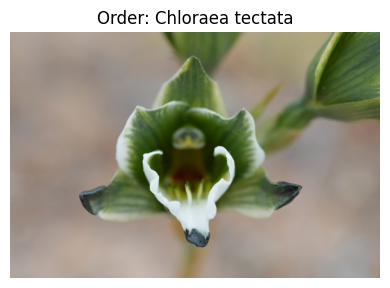


Attempting to get image for Order: Chloraea disoides (GBIF ID: 6552303738)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/734534807/original.jpg


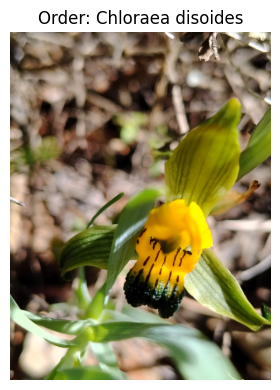


Attempting to get image for Order: Chloraea chrysantha (GBIF ID: 6552221944)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/735941076/original.jpg


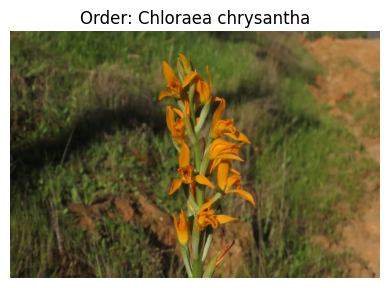


Attempting to get image for Order: Chloraea lamellata (GBIF ID: 6551942530)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/595539915/original.jpg


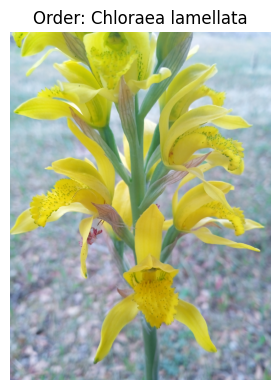


Attempting to get image for Order: Chloraea prodigiosa (GBIF ID: 6551307700)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/595521283/original.jpg


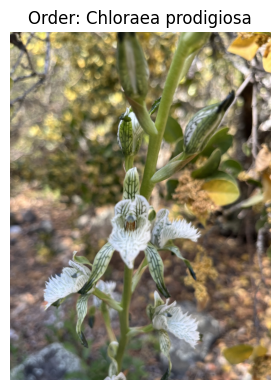


Attempting to get image for Order: Chloraea magellanica (GBIF ID: 6550921874)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/607314251/original.jpg


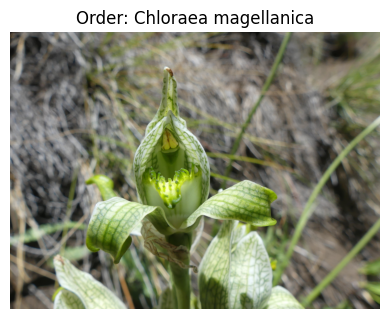


Attempting to get image for Order: Chloraea longipetala (GBIF ID: 6550895429)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/606768909/original.jpg


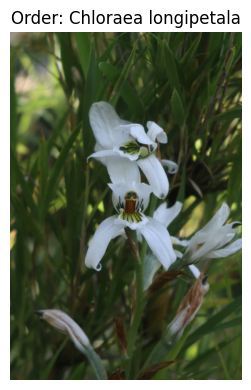


Attempting to get image for Order: Chloraea cylindrostachya (GBIF ID: 6520725345)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/727092205/original.jpg


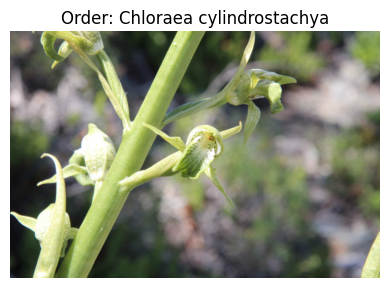


Attempting to get image for Order: Chloraea bletioides (GBIF ID: 6520643494)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/726707817/original.jpg


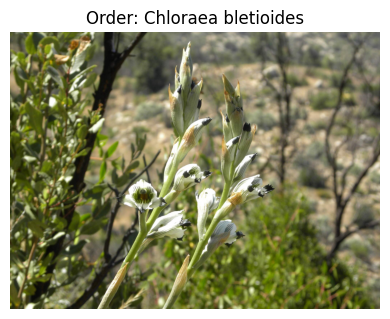


Attempting to get image for Order: Chloraea apinnula (GBIF ID: 6519277069)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/624871489/original.jpg


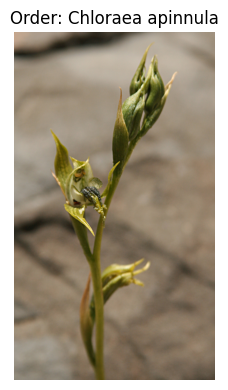


Attempting to get image for Order: Chloraea nudilabia (GBIF ID: 6441339601)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/597696018/original.jpg


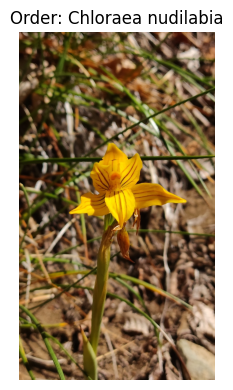


Attempting to get image for Order: Chloraea fonkii (GBIF ID: 6179195616)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/624906105/original.jpg


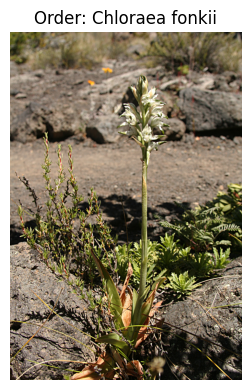


Attempting to get image for Order: Chloraea bidentata (GBIF ID: 6179126024)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/624901334/original.jpg


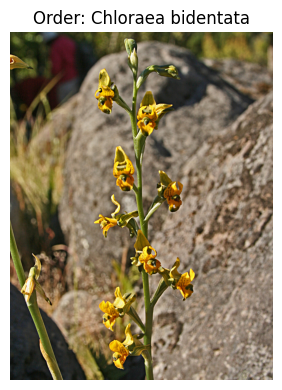


Attempting to get image for Order: Chloraea volkmannii (GBIF ID: 6178436594)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/624909882/original.jpg


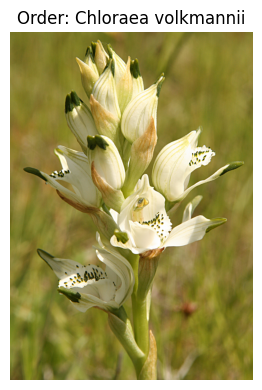


Attempting to get image for Order: Chloraea cristata (GBIF ID: 6147350623)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/614527648/original.jpg


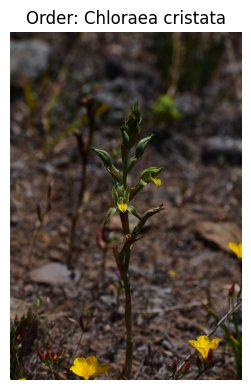


Attempting to get image for Order: Chloraea heteroglossa (GBIF ID: 6131444059)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/610231689/original.jpg


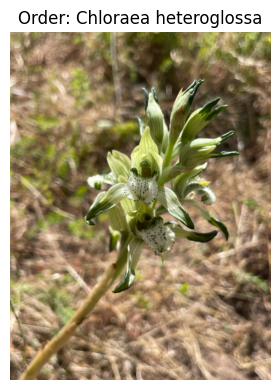


Attempting to get image for Order: Chloraea grandiflora (GBIF ID: 6131238486)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/607313656/original.jpg


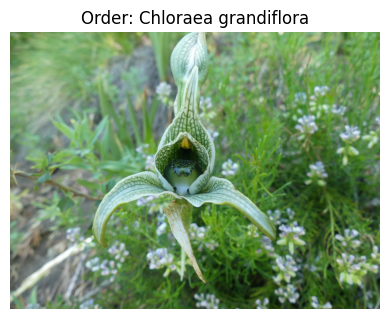


Attempting to get image for Order: Chloraea speciosa (GBIF ID: 5938246663)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/604676539/original.jpg


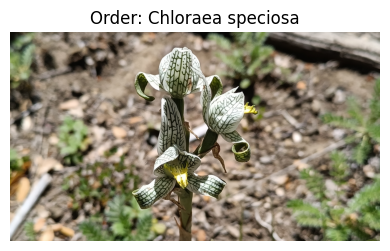


Attempting to get image for Order: Chloraea lechleri (GBIF ID: 5920211502)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/594224929/original.jpg


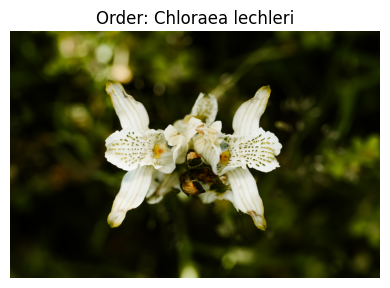


Attempting to get image for Order: Chloraea philippii (GBIF ID: 5188314485)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/458798875/original.jpg


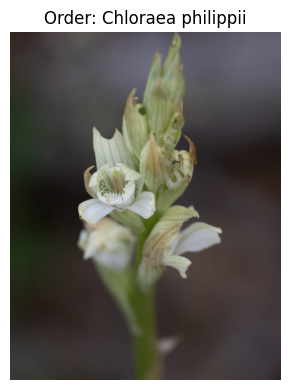


Attempting to get image for Order: Chloraea cuneata (GBIF ID: 5139945535)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/193150961/original.jpg


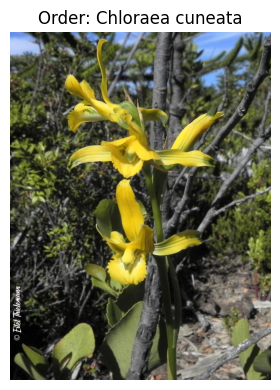


Attempting to get image for Order: nan (GBIF ID: 3985752959)
  Using direct image URL: https://inaturalist-open-data.s3.amazonaws.com/photos/242741704/original.jpeg


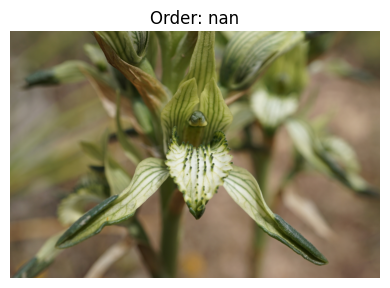


Finished image extraction and plotting.


In [ ]:
import requests
from bs4 import BeautifulSoup
from skimage import io
import matplotlib.pyplot as plt
import pandas as pd

# Ensure df_reduced is available. It was created previously in the notebook.
# For robustness, you could uncomment the following line if df_reduced might not be available:
# df_reduced = df[['order','gbifID']].drop_duplicates(subset = ['order'])

print("Starting image extraction and plotting for each unique order...")

for i in range(len(df_reduced)): # Iterate through the DataFrame of unique orders
  gbif_id = df_reduced.iloc[i]['gbifID']
  species = df_reduced.iloc[i]['species']

  print(f"\nAttempting to get image for Order: {species} (GBIF ID: {gbif_id})")

  image_url = None
  try:
    # Fetch occurrence details from GBIF
    results = occ.get(key=gbif_id)

    if 'media' in results and len(results['media']) > 0: # Check if media exists
        original_url = results['media'][0]['identifier']

        # Check if the URL is an iNaturalist observation page
        if "inaturalist.org/observations/" in original_url:
            print(f"  Parsing iNaturalist page for direct image: {original_url}")
            try:
                # Fetch the iNaturalist page content
                response = requests.get(original_url, timeout=10) # Added a timeout for network request
                response.raise_for_status() # Raise an HTTPError for bad responses (4xx or 5xx)

                # Parse the HTML to find the direct image URL
                soup = BeautifulSoup(response.content, 'html.parser')
                og_image_tag = soup.find('meta', property='og:image')

                if og_image_tag and 'content' in og_image_tag.attrs:
                    image_url = og_image_tag['content']
                    print(f"  Found direct image URL: {image_url}")
                else:
                    print(f"  Warning: Could not find 'og:image' meta tag on iNaturalist page for GBIF ID {gbif_id}.")
            except requests.exceptions.Timeout:
                print(f"  Warning: Request to {original_url} timed out after 10 seconds.")
            except requests.exceptions.RequestException as e:
                print(f"  Warning: Error fetching iNaturalist page {original_url}: {e}")
        else:
            # If not an iNaturalist observation page, assume it's a direct image URL
            image_url = original_url
            print(f"  Using direct image URL: {image_url}")
    else:
        print(f"  No media identifier found for GBIF ID {gbif_id}.")

    if image_url:
        try:
            # Display the image
            fig, ax = plt.subplots(1, 1, figsize=(4, 4))
            image = io.imread(image_url)
            ax.imshow(image)
            ax.axis('off')
            ax.set_title(f"Order: {species}")
            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f"  Error loading or displaying image from {image_url}: {e}")
    else:
        print(f"  No image available to display for specia: {species} (GBIF ID: {gbif_id}).")

  except Exception as e:
    print(f"  An unexpected error occurred while processing GBIF ID {gbif_id} (specie: {species}): {e}")

print("\nFinished image extraction and plotting.")

In [ ]:
def get_urlimage(genus):
  specimen = df_reduced[df_reduced['species'] == genus]
  id = specimen['gbifID'].iloc[0]
  speciess = specimen['species'].iloc[0]
  results = occ.get(key=id)
  original_url = results['media'][0]['identifier']
  return original_url, speciess

In [ ]:
original_url, speciess = get_urlimage('Chloraea lamellata')

In [ ]:
def read_image(original_url):
  image = io.imread(original_url)
  return image


In [ ]:
image = read_image(original_url)

In [ ]:
def plot_image(i,s):
  fig, ax = plt.subplots(1, 1, figsize=(6, 6))
  ax.imshow(i)
  plt.suptitle(s)
  ax.axis('off')
  plt.tight_layout()
  plt.show()

  print(f'shape: {image.shape}')


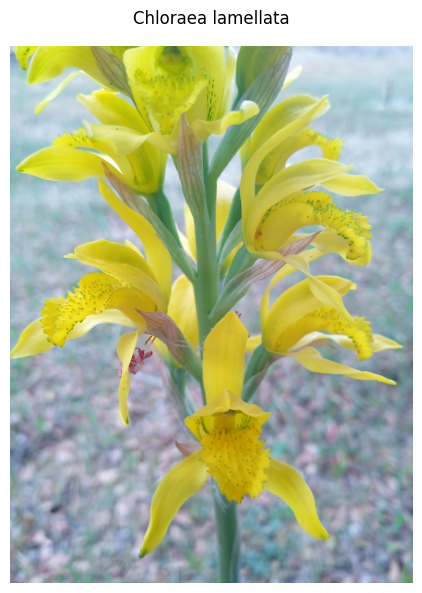

shape: (2048, 1536, 3)


In [ ]:
plot_image(image,speciess)

In [ ]:
def split_channels(image):
  i_r = image[:,:,0]
  i_g = image[:,:,1]
  i_b = image[:,:,2]

  return [i_r, i_g, i_b]

In [ ]:
def split_channels_flatten(image):
  i_r_flatten = image[:,:,0].flatten()
  i_g_flatten = image[:,:,1].flatten()
  i_b_flatten = image[:,:,2].flatten()

  return [i_r_flatten, i_g_flatten, i_b_flatten]

In [ ]:
def plot_channels(image):
  image_red, image_green, image_blue = split_channels(image)
  fig, axs = plt.subplots(1, 3, figsize=(15, 5))
  axs[0].imshow(image_red, cmap='Reds')
  axs[1].imshow(image_green, cmap='Greens')
  axs[2].imshow(image_blue, cmap='Blues')
  axs[0].axis('off')
  axs[1].axis('off')
  axs[2].axis('off')
  axs[0].set_title('Canal R')
  axs[1].set_title('Canal G')
  axs[2].set_title('Canale B')
  plt.show()

In [ ]:
def plot_channel_hist(image):
  image_red, image_green, image_blue = split_channels_flatten(image)
  bins = 24

  fig, axs = plt.subplots(1, 3, figsize=(15, 5))

  sns.histplot(image_red, color='red',kde=True, ax=axs[0], bins=bins)
  sns.histplot(image_green, color='green',kde=True, ax=axs[1], bins=bins)
  sns.histplot(image_blue, color='blue',kde=True, ax=axs[2], bins=bins)
  axs[0].axis('off')
  axs[1].axis('off')
  axs[2].axis('off')
  axs[0].set_title('Canal R')
  axs[1].set_title('Canal G')
  axs[2].set_title('Canal B')
  plt.show()

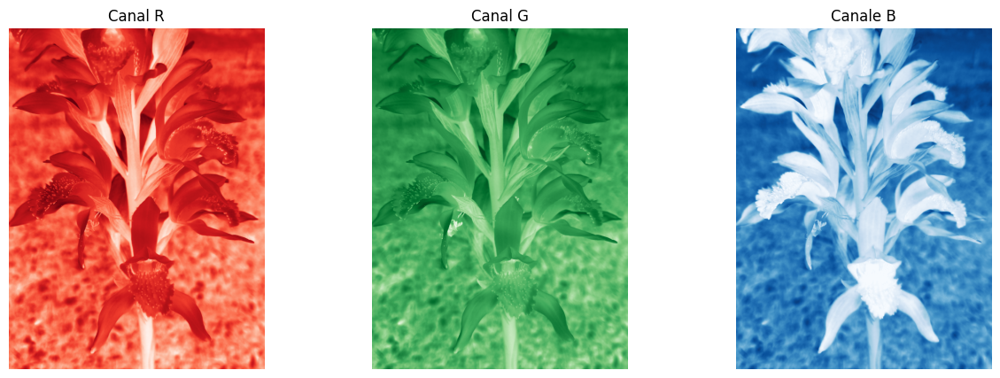

In [ ]:
plot_channels(image)

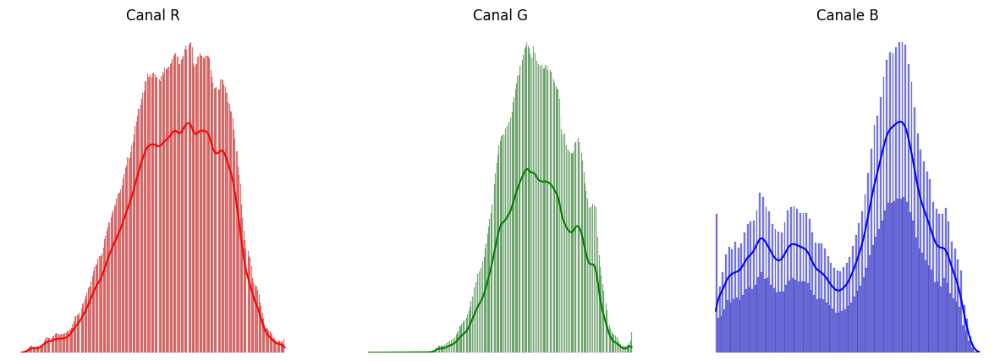

In [ ]:
plot_channel_hist(image)

In [ ]:
flatten_image = image.flatten()


<Axes: ylabel='Frequency'>

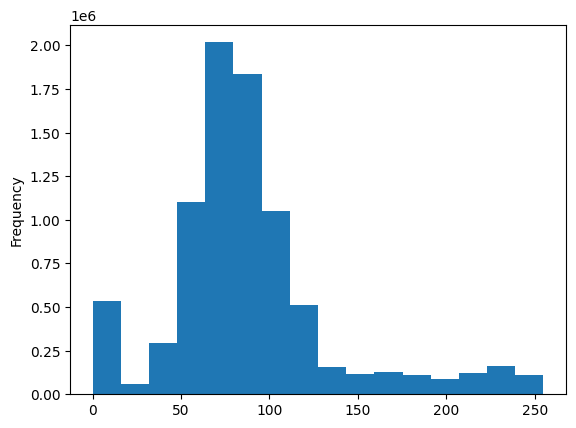

In [ ]:
pd.Series(flatten_image).plot(kind='hist', bins=16)

[IMG01_SimpleColorSegmentation](https://colab.research.google.com/drive/1gfSdlVgzd3abygf8XB0I2F62rpzlh8SK#scrollTo=HKzfhtR9P9ef). Domingo Mery

In [ ]:
import numpy as np
from  cv2 import imread
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt

In [ ]:
def howis(img):
  print('size = ',img.shape)
  print('max  = ',np.max(img))
  print('min  = ',np.min(img))

In [ ]:
import cv2
Icv = cv2.resize(image, (720, 720))

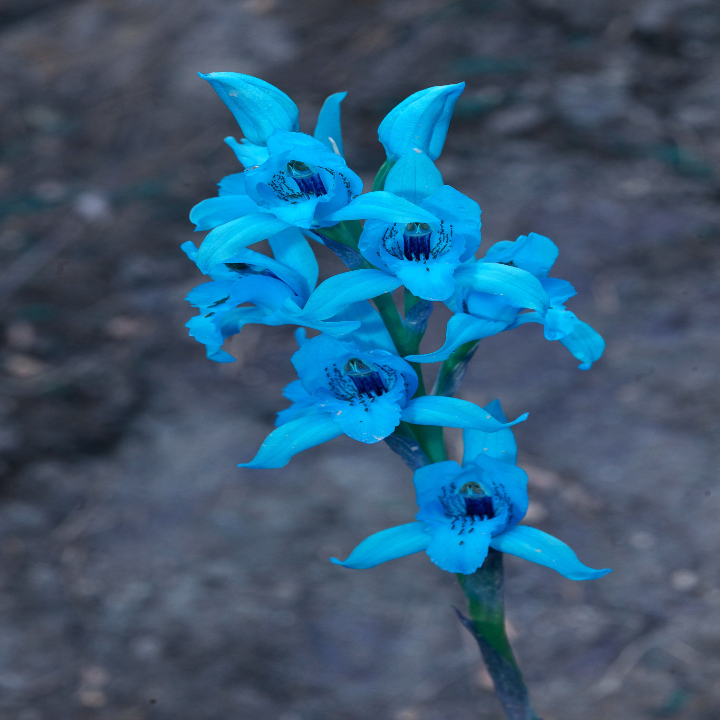

size =  (720, 720, 3)
max  =  255
min  =  0


In [ ]:
cv2_imshow(Icv)
howis(Icv)

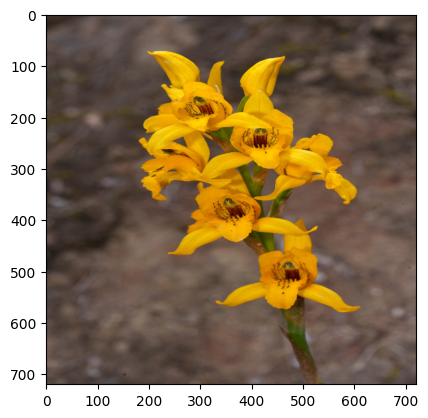

In [ ]:
I2 = Icv[:,:,[0,1,2]]             # BGR to RGB conversion
plt.imshow(I2)
plt.show()

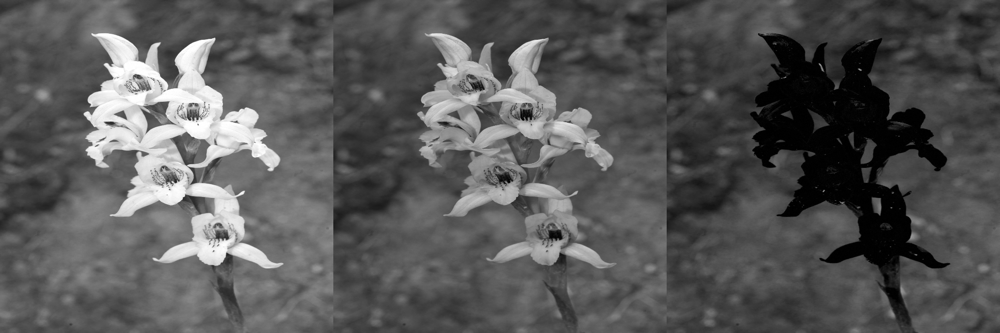

In [ ]:
R = I2[:,:,0]
G = I2[:,:,1]
B = I2[:,:,2]
RGB = np.concatenate((R,G,B),axis=1)
cv2_imshow(RGB)

size =  (720, 720)
max  =  250
min  =  22


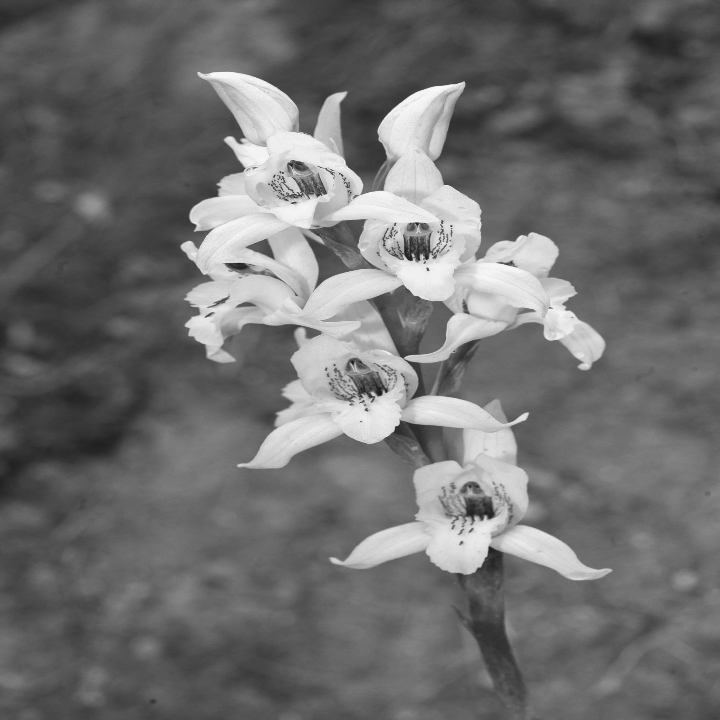

In [ ]:
Rd = R.astype(float)
Gd = G.astype(float)
Bd = B.astype(float)
# weighted average
#k  = (1/3,1/3,1/3)
k  = (0.75,0.25,0)
Zd = k[0]*Rd+k[1]*Gd+k[2]*Bd
Z  = Zd.astype(int)
howis(Z)
cv2_imshow(Z)

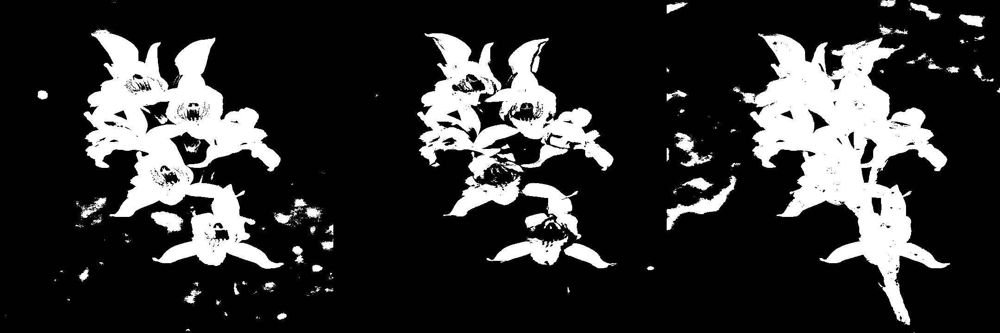

In [ ]:
Sr = R>128
Sg = G>128
Sb = B<40
Srgb = np.concatenate((Sr,Sg,Sb),axis=1)
cv2_imshow(Srgb*255)

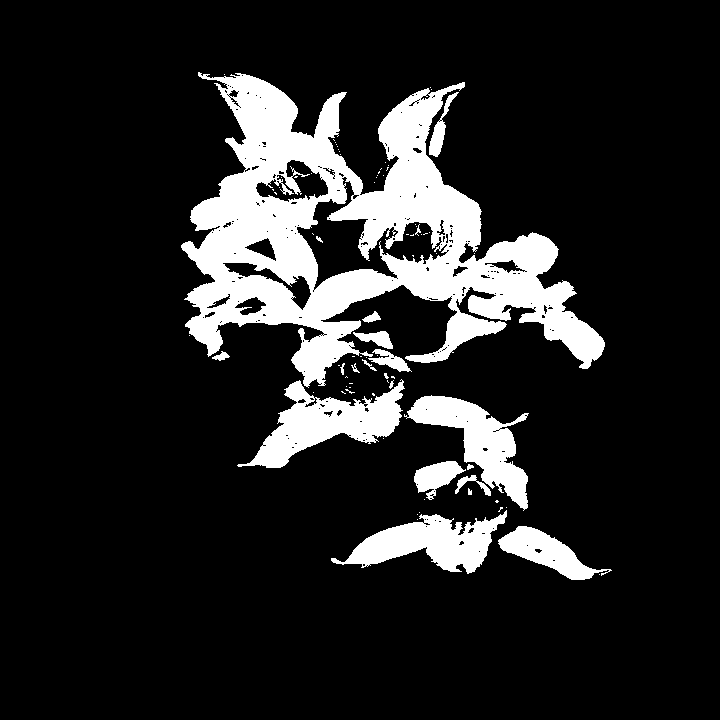

In [ ]:
Srg = np.logical_and(Sr,Sg)
S   = np.logical_and(Srg,Sb)
cv2_imshow(S*255)

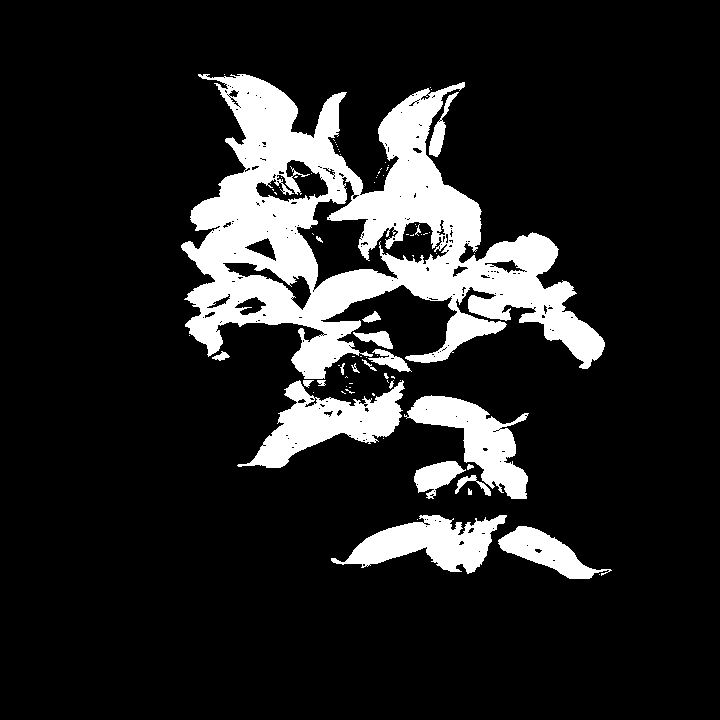

In [ ]:
(N,M) = S.shape
Q = S
for i in range(N):
  s = np.sum(S[i,:])
  if s<20:
    Q[i,:] = 0
cv2_imshow(Q*255)

In [ ]:
imin = 1000
imax = 0
jmin = 1000
jmax = 0
for i in range(N):
  for j in range(M):
    if Q[i,j]>0:
      if i<imin:
        imin = i
      if i>imax:
        imax = i
      if j<jmin:
        jmin = j
      if j>jmax:
        jmax = j

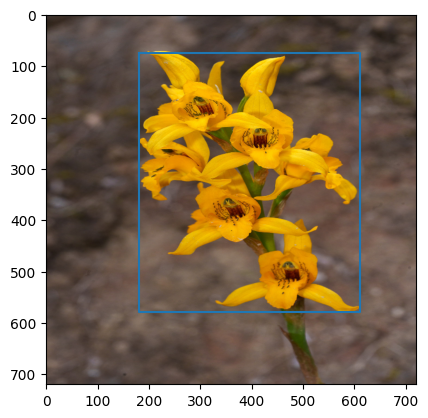

In [ ]:
y = [imin,imin,imax,imax,imin]
x = [jmin,jmax,jmax,jmin,jmin]
plt.imshow(I2)
plt.plot(x,y)
plt.show()

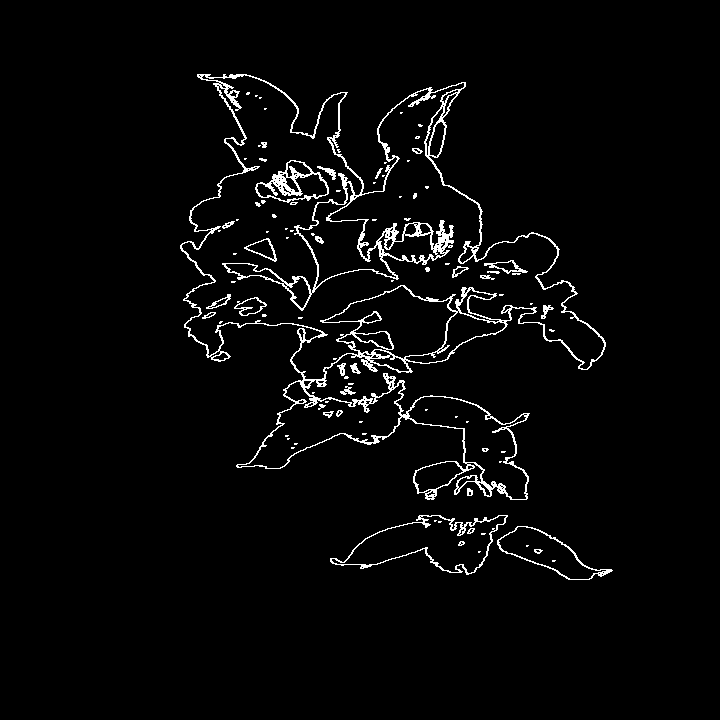

In [ ]:
E = np.zeros((N,M),np.uint8)
for i in range(N):
  for j in range(1,M):
    if Q[i,j]!=Q[i,j-1]:
      E[i,j]   = 1
      E[i,j-1] = 1
for i in range(1,N):
  for j in range(M):
    if Q[i-1,j]!=Q[i,j]:
      E[i,j]   = 1
      E[i,j-1] = 1
cv2_imshow(E*255)


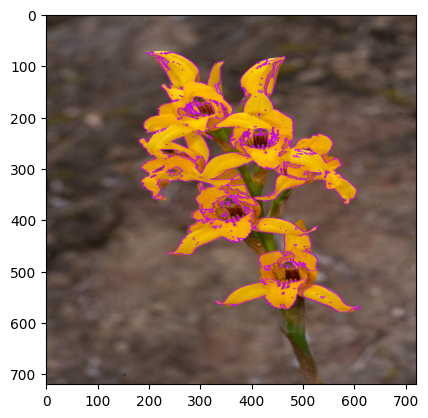

In [ ]:
for i in range(N):
  for j in range(M):
    if E[i,j]==1:
      Icv[i,j,:] = [200,0,255]
Icv = Icv[:,:,[0,1,2]]             # BGR to RGB conversion
plt.imshow(Icv)
plt.show()


In [ ]:
I_gray = cv2.cvtColor(I2, cv2.COLOR_RGB2GRAY)

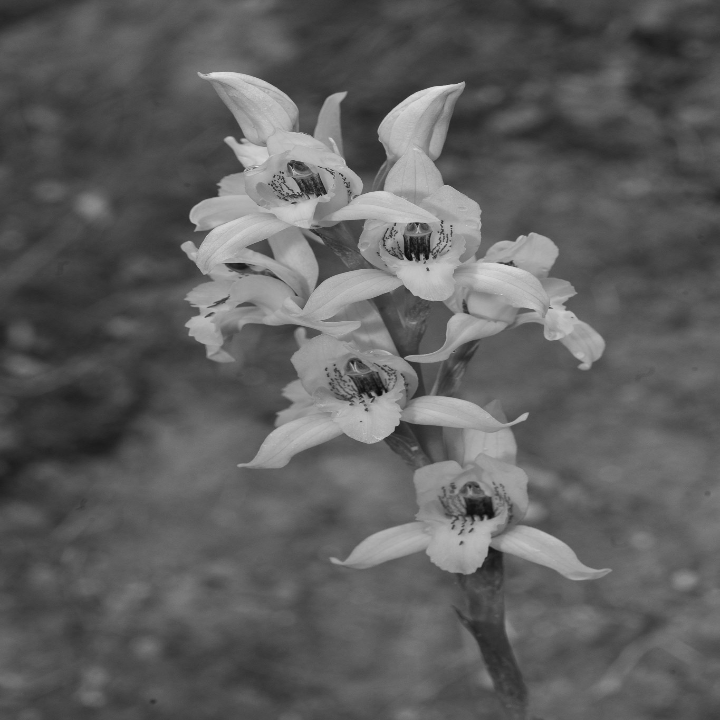

In [ ]:
cv2_imshow(I_gray)


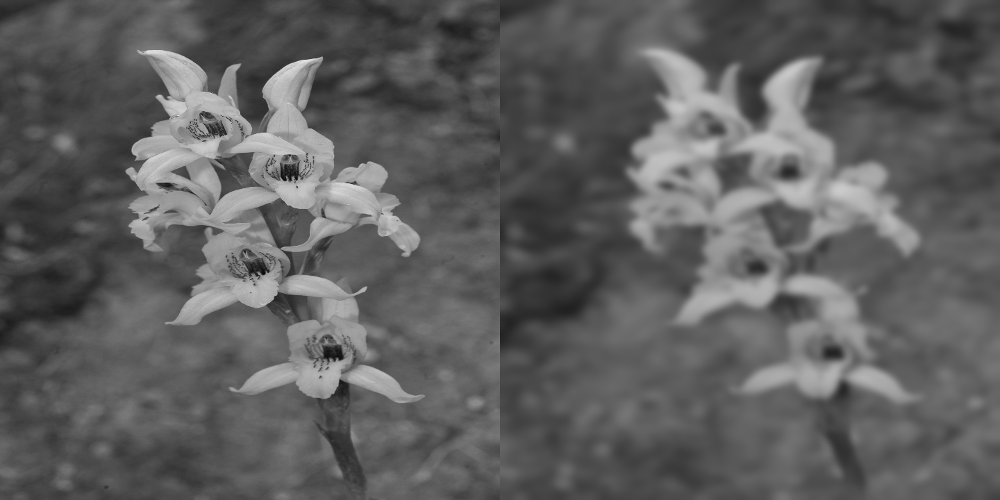

In [ ]:
# FGaussian Filtering
s      = 39
kernel = cv2.getGaussianKernel(s, s/8.5)        # Gaussian s x 1  (s = size, s/8.5 = sigma)
window = np.outer(kernel, kernel.transpose())   # Gaussian s x s pixels
L      = cv2.filter2D(I_gray,-1,window)
Z      = np.concatenate((I_gray ,L),axis=1)
cv2_imshow(Z)

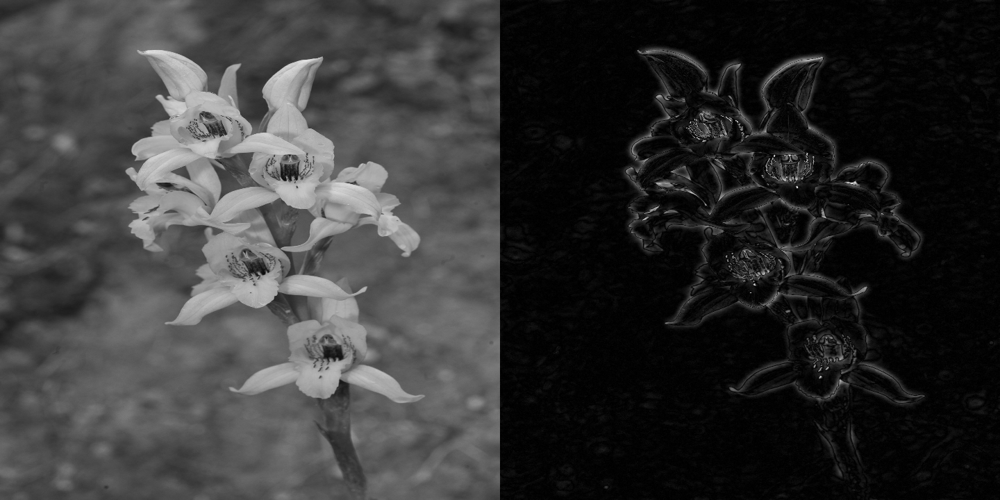

In [ ]:
# High Pass Filtering
Id = I_gray.astype(float)
Ld = L.astype(float)
Hd = Id-Ld

# Visualization
H = np.abs(Hd)
H = H-np.min(H)
H = H/np.max(H)*255
Z = np.concatenate((I_gray,H),axis=1)
cv2_imshow(Z)

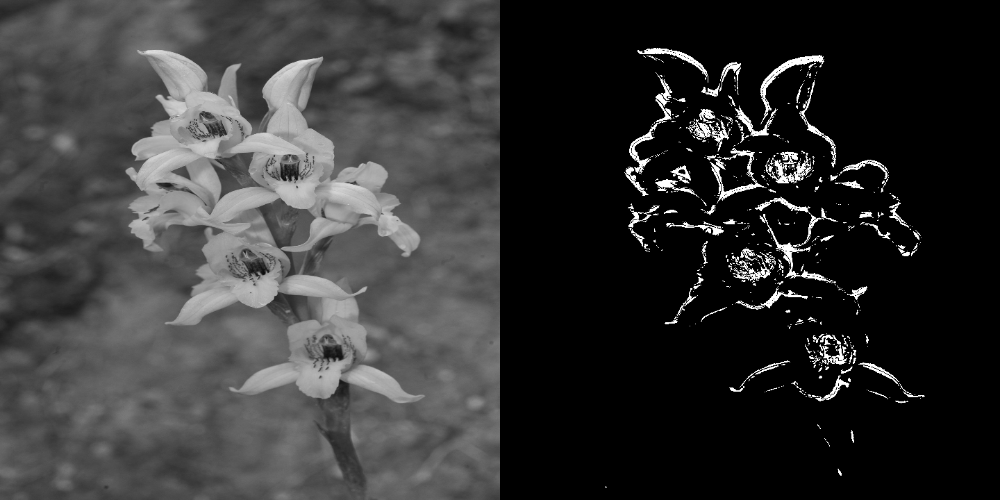

In [ ]:
# Edge detection using High Pass Filtering
E = (H>50)*255
Z = np.concatenate((I_gray,E),axis=1)
cv2_imshow(Z)

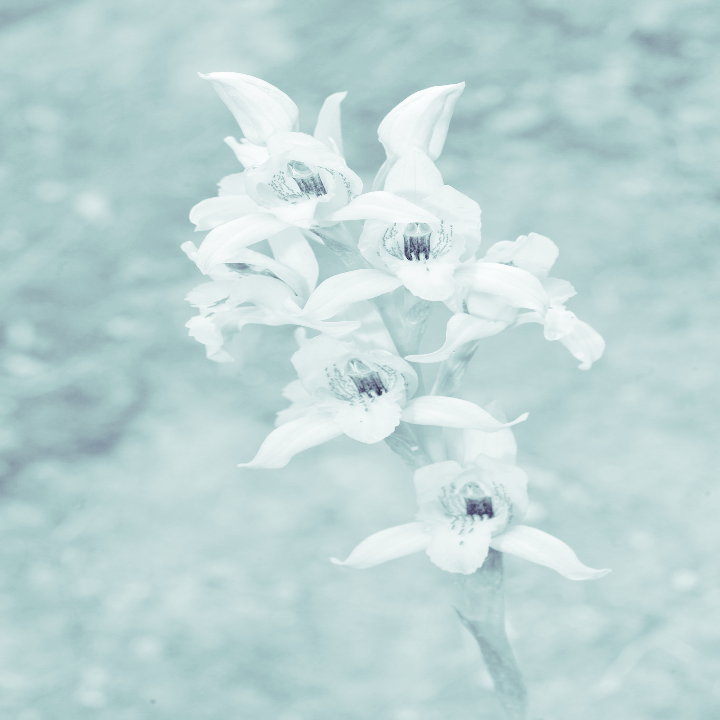

In [ ]:
L = np.log(G+1)
L = L/np.max(L)*255
Li = L.astype(np.uint8)


Lc = cv2.applyColorMap(Li, cv2.COLORMAP_BONE)

cv2_imshow(Lc)

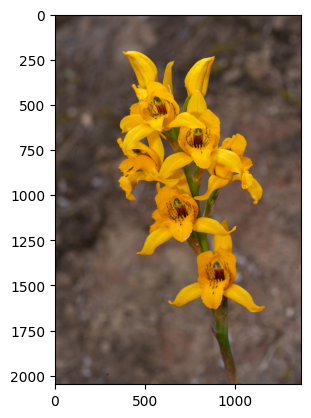

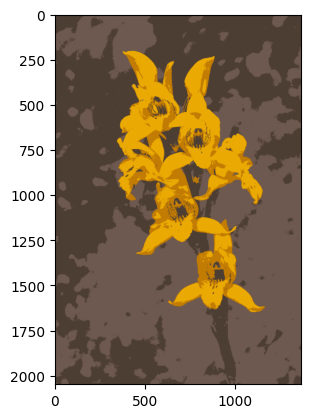

In [ ]:
# convert to RGB
image2 = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image2 = image2[:,:,[2,1,0]]             # BGR to RGB conversion

plt.imshow(image2)
plt.show()

# reshape the image to a 2D array of pixels and 3 color values (RGB)
pixel_values = image2.reshape((-1, 3))
# convert to float
pixel_values = np.float32(pixel_values)

# define stopping criteria
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

# Define the number of clusters for K-Means (K is an integer)
k = 4
compactness, labels, (centers) = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# convert back to 8 bit values
centers = np.uint8(centers)

# flatten the labels array
labels = labels.flatten()

# convert all pixels to the color of the centroids
segmented_image = centers[labels]

# reshape back to the original image dimension
segmented_image = segmented_image.reshape(image2.shape)

# show the image
plt.imshow(segmented_image)
plt.show()